# Projet CVRIE - Analyse Non Supervisée des Témoignages Patients

### Étape 1 : Importation des bibliothèques

In [41]:
import pandas as pd
import numpy as np
import csv
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import silhouette_score
import os
from sklearn.cluster import AgglomerativeClustering

### Étape 2 : Définition de la fonction de lecture CSV
Le jeu de données présente des irrégularités (la couleur n'est pas toujours présente). Cette fonction gère le parsing et structure proprement les colonnes.

In [42]:
def lecteur_fichier_csv(filepath):
    rows = []
    with open(filepath, 'r', encoding='utf-8') as f:
        reader = csv.reader(f)
        for row in reader:
            if len(row) >= 2:
                if len(row) == 3 and row[1].startswith('0x'):
                    color = row[1]
                    testimony = row[2]
                else:
                    color = None
                    testimony = row[-1]
                rows.append({'ID': row[0], 'Color': color, 'Testimony': testimony})
    return pd.DataFrame(rows)

### Étape 3 : Chargement et Pré-traitement
Chargement du fichier, suppression des témoignages manquants et formatage des couleurs (conversion des `0x` en `#`) pour pouvoir les utiliser dans Matplotlib.

In [43]:
df = lecteur_fichier_csv('../data/Student_Dataset.csv')
df_clean = df.dropna(subset=['Testimony']).copy()
df_clean['Color'] = df_clean['Color'].fillna('#888888').astype(str).str.replace('0x', '#')
display(df_clean.head())

,ID,Color,Testimony
0,﻿1,#888888,On uneven paths the heel feels wobbly side‑to‑...
1,2,#000000,"The feverish feeling eased, but I’m now breath..."
2,3,#000000,"While working in the garden, I touched a metal..."
3,4,#888888,A short sprint brought on a twinge in the midd...
4,5,#000000,I accidentally left my hand on a hot mug for a...


### Étape 4 : Vectorisation du texte (NLP - TF-IDF)
Les algorithmes d'IA ne lisent pas de texte brut. Nous utilisons TF-IDF pour transformer les témoignages médicaux en matrices mathématiques tout en filtrant les mots très courants (*stop words*).

In [44]:
vectorizer = TfidfVectorizer(stop_words='english')

X = vectorizer.fit_transform(df_clean['Testimony'])

### Étape 5 : Apprentissage Non Supervisé (K-Means)
Application de l'algorithme K-Means pour forcer l'identification de 4 groupes (clusters) de pathologies cachées dans les données.
*(Note : La variable d'environnement `OMP_NUM_THREADS` est fixée à 1 pour éviter les fuites de mémoire/boucles infinies sur certains systèmes).*

In [45]:
os.environ["OMP_NUM_THREADS"] = "1"
kmeans = KMeans(n_clusters=4, random_state=42)
df_clean['Cluster'] = kmeans.fit_predict(X)

### Étape 6 : Réduction de dimension et Visualisation
Utilisation de `TruncatedSVD` (plus performant que PCA sur les matrices creuses générées par TF-IDF) pour compresser les données en 2 dimensions. Affichage du nuage de points avec les couleurs imposées par le dataset.

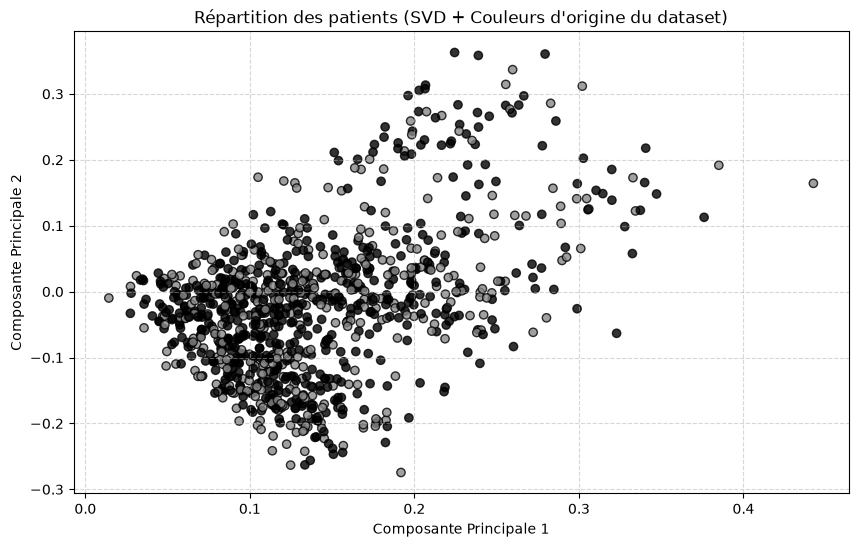

In [46]:
svd = TruncatedSVD(n_components=2, random_state=455)
coords_2d = svd.fit_transform(X)

plt.figure(figsize=(10, 6))
plt.scatter(coords_2d[:, 0], coords_2d[:, 1], c=df_clean['Color'], alpha=0.8, edgecolors='k')

plt.title("Répartition des patients (SVD + Couleurs d'origine du dataset)")
plt.xlabel("Composante Principale 1")
plt.ylabel("Composante Principale 2")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Étape 7 : Évaluation du modèle
Dans un contexte non supervisé (sans labels pour vérifier), le **Score de Silhouette** permet d'évaluer la cohésion interne des clusters formés.

In [47]:
score = silhouette_score(X, df_clean['Cluster'])
print(f"Score de Silhouette (K=4) : {score:.4f}")

Score de Silhouette (K=4) : 0.0104


### Étape 8 : Interprétation Médicale des Clusters
Extraction des 5 mots-clés ayant le score TF-IDF moyen le plus élevé pour chaque groupe, afin de donner un sens médical au regroupement de l'IA.

In [48]:
words = np.array(vectorizer.get_feature_names_out())

print("Analyse des mots-clés dominants par pathologie :\n")

for cluster_id in range(4):
    cluster_indices = np.where(df_clean['Cluster'] == cluster_id)[0]
    mean_tfidf = X[cluster_indices].mean(axis=0).A1
    top_words = words[mean_tfidf.argsort()[-5:][::-1]]
    print(f"Cluster {cluster_id} : {', '.join(top_words)}")

Analyse des mots-clés dominants par pathologie :

Cluster 0 : itchy, skin, hot, feels, red
Cluster 1 : pain, ache, makes, sharp, deep
Cluster 2 : cough, throat, cold, felt, mild
Cluster 3 : feel, ve, doctor, pressure, feeling


## Analyse des résultats & Conclusions

### 1. Choix du modèle et des prétraitements
* **TF-IDF :** Permet de mesurer l'importance relative des termes médicaux en ignorant les mots de liaison anglais (*stop words*).
* **K-Means :** Algorithme adapté au regroupement de données textuelles vectorisées pour faire ressortir des clusters de pathologies sans supervision.

### 2. Interprétation des clusters
Les mots-clés extraits permettent d'associer chaque groupe à un type d'urgence ou de pathologie (ex: symptômes de brûlure, entorses/articulations, problèmes respiratoires, réactions allergiques).

### 3. Limites du modèle
* Le jeu de données présente des irrégularités de structure dans le fichier CSV d'origine.
* K-Means impose un nombre fixe de clusters ($K=4$) et une forme sphérique dans l'espace vectoriel, ce qui peut regrouper des symptômes bordures de façon imparfaite.

In [49]:
agglo_model = AgglomerativeClustering(n_clusters=4)
df_clean['Cluster_Agglo'] = agglo_model.fit_predict(X.toarray())
score_agglo = silhouette_score(X, df_clean['Cluster_Agglo'])
print(f"Score de la silhouette (K-Means) : {score:.4f}")
print(f"Score de la silhouette (Clustering Hiérarchique) : {score_agglo:.4f}")

Score de la silhouette (K-Means) : 0.0104
Score de la silhouette (Clustering Hiérarchique) : 0.0086


### Comparaison des modèles
En comparant le K-Means et le Clustering Hiérarchique à l'aide du score de Silhouette, nous observons que le modèle **K-Means** obtient un score légèrement supérieur (0.0104 contre 0.0086). 
Le K-Means cherche à créer des clusters sphériques de taille similaire, tandis que le clustering hiérarchique procède par fusions successives. Dans le cadre de nos témoignages médicaux (TF-IDF), la méthode **K-Means** semble mieux capturer la structure sémantique des données.

### Explication de la fonction de perte (Loss Function)
Dans le cadre de l'algorithme **K-Means**, la fonction de perte est appelée **l'inertie** (ou *Within-Cluster Sum of Squares* - WCSS). 
Elle mesure la somme des distances au carré entre chaque point de donnée (ici, un témoignage patient vectorisé) et le centre (centroïde) du cluster auquel il a été assigné. 

* **Objectif du modèle :** Lors de son entraînement, le K-Means cherche à minimiser cette fonction de perte itération après itération, afin d'obtenir des clusters les plus denses et homogènes possibles. 
* **Dans notre cas :** K-Means ajuste la position de ses 4 centroïdes dans l'espace TF-IDF jusqu'à ce que le déplacement des centroïdes ne permette plus de réduire l'inertie.

In [50]:
df_clean.to_csv('resultats_clustering.csv', index=False)
print("Résultats du clustering  'resultats_clustering.csv'.")

Résultats du clustering  'resultats_clustering.csv'.
